# Notebook 08: Phase 2 Hybrid H1 — Latent-Space GMM, Theoretical Evidence & Ablations
**Author:** Apoorva Choudhary (Task P2_02)  
**Project:** Card Fraud Triage (GMM vs. Autoencoder) — Team T033  
**Phase:** Phase 2 (Deep Learning & Hybrid Anomaly Detection)

---

## Objectives & Leakage Guarantees
1. **Upstream Encoder Interface (`src/autoencoder.py`):** Load Vani's trained Autoencoder (`ae_best.pt`, `UndercompleteAE`, $d_{\text{in}}=31 \to k=12$, `base` features) and ablation checkpoints (`ae_latent_k{2,4,8,16}.pt`) via `load_vani_encoder` and `encode_splits` (`shuffle=False`, `eval()`, `torch.no_grad()`).
2. **Zero-Contamination Density Fitting:** Fit `GaussianMixture` **exclusively** on legitimate training latent vectors (`Z_train_legit`, `Class == 0`).
3. **Validation-Only Selection:** Compare unsupervised $\arg\min \text{BIC}_Z$ vs. validation $\arg\max \text{PR-AUC}$ over 120 configurations (`cov_type × K × reg_covar`); test labels are never used for selection.
4. **Score Contract:** Export 1-D `float32` negative log-likelihood $-\ln p(\mathbf{z})$ arrays to `results/scores/hybrid_latentgmm_{val,test}.npy` (higher score = more anomalous).
5. **Evidence (i)–(v) & Task C Ablations:** Quantify parameter complexity, condition numbers / `reg_covar` sensitivity, 5-seed EM variance, latent vs. ambient Gaussianity, failure/complementarity diagnostics, and multi-dimension (`k ∈ {2,4,8,12,16}`) 3-seed ablations.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import CFG
from src.data import get_features
from src.hybrid_latent_gmm import (
    discover_ablation_checkpoints,
    encode_splits,
    load_vani_encoder,
)
from src.metrics import pr_auc, recall_at_fpr, roc_auc
from src.utils import load_scores

print("Repo Root:", ROOT)


2026-11-12 17:25:37 | INFO     | src.data | Registered additional feature sets from src.features: ['raw', 'engineered', 'fe_norm_outliers', 'norm_outliers', 'fe_pca_whitened', 'pca_whitened', 'fe_robust_amount', 'robust_amount', 'fe_yeojohnson_amount', 'yeojohnson_amount', 'fe_time_risk', 'time_risk', 'fe_val_selected', 'val_selected']


Repo Root: /Users/apoorvachoudhary/Desktop/T033-CardFraudDetection-AML-DL


## 1. Upstream Encoder Verification (`src/autoencoder.py`)
Verify Vani's chosen checkpoint (`ae_best.pt`) and ablation checkpoints (`ae_latent_k{2,4,8,16}.pt`) load cleanly and preserve split row counts.

In [2]:
encoder, meta = load_vani_encoder(ROOT / "results/models/ae_best.pt")
ablation_ckpts = discover_ablation_checkpoints(ROOT / "results/models")
print("Chosen encoder:", meta)
print("Config:", encoder.get_config())
print("Ablation checkpoints:", {k: p.name for k, p in ablation_ckpts.items()})

splits = get_features("base")
latent_splits = encode_splits(encoder, splits, feature_set="base", encoder_id="ae_best")
print(f"Latent shapes -> train_legit: {latent_splits.Z_train_legit.shape}, val: {latent_splits.Z_val.shape}, test: {latent_splits.Z_test.shape}")


2026-11-12 17:25:39 | INFO     | src.data | Loading raw data from /Users/apoorvachoudhary/Desktop/T033-CardFraudDetection-AML-DL/data/raw/creditcard.csv …


Chosen encoder: {'checkpoint_path': '/Users/apoorvachoudhary/Desktop/T033-CardFraudDetection-AML-DL/results/models/ae_best.pt', 'loader': 'src.autoencoder.load_autoencoder'}
Config: {'model_type': 'UndercompleteAE', 'd_in': 31, 'latent_dim': 12, 'hidden': [32, 16], 'act': 'leaky_relu', 'dropout': 0.0, 'batchnorm': False, 'n_params': 3531}
Ablation checkpoints: {2: 'ae_latent_k2.pt', 4: 'ae_latent_k4.pt', 8: 'ae_latent_k8.pt', 16: 'ae_latent_k16.pt'}


2026-11-12 17:25:39 | INFO     | src.data | Loaded: 284807 rows × 31 cols


2026-11-12 17:25:39 | WARNING  | src.data | Found 1081 exact duplicate rows (0.3796% of dataset).


2026-11-12 17:25:39 | INFO     | src.data | Keeping duplicates (drop_duplicates=false in config). Set drop_duplicates: true to remove them.


2026-11-12 17:25:39 | INFO     | src.data | Frauds: 492 / 284807  (base rate = 0.1727%)


... (4 outputs left out)

2026-11-12 17:25:44 | INFO     | src.data | Time ordering check: train_max=120396.0  val_min=120396.0  val_max=145247.0  test_min=145248.0


2026-11-12 17:25:44 | INFO     | src.data | [base] X_train_legit=(170524, 31)  X_val=(56961, 31)  X_test=(56962, 31)  features=31


2026-11-12 17:25:44 | INFO     | src.data | get_features('base') done. X_train_legit=(170524, 31) X_val=(56961, 31) X_test=(56962, 31)


Latent shapes -> train_legit: (170524, 12), val: (56961, 12), test: (56962, 12)


## 2. Task A — Latent-GMM Model Selection, Official Metrics & Parent Comparison

In [3]:
sel_df = pd.read_csv(ROOT / "results/tables/latentgmm_selection_comparison.csv", index_col=0)
chosen_df = pd.read_csv(ROOT / "results/tables/latentgmm_selected_config.csv", index_col=0)
metrics_df = pd.read_csv(ROOT / "results/tables/latentgmm_metrics.csv", index_col=0)
ci_df = pd.read_csv(ROOT / "results/tables/latentgmm_parent_comparison.csv", index_col=0)
paired_df = pd.read_csv(ROOT / "results/tables/latentgmm_paired_bootstrap.csv", index_col=0)

print("--- Selection Comparison (BIC vs Val PR-AUC) ---")
display(sel_df)
print("--- Selected Configuration ---")
display(chosen_df)
print("--- Official H1 Metrics ---")
display(metrics_df.loc[["PR-AUC", "ROC-AUC", "recall@FPR=0.001", "recall@FPR=0.005", "recall@FPR=0.010", "precision@K=50", "precision@K=100", "precision@K=200"]])


--- Selection Comparison (BIC vs Val PR-AUC) ---


,criterion,latent_dim,covariance_type,n_components,reg_covar,free_parameters,train_bic,val_legit_bic,val_pr_auc,val_recall@0.5%
0,Unsupervised (Min Train-Legit BIC),12,full,16,0.000001,1455,915364.39,1286219.13,0.05204,0.40351
1,Unsupervised (Min Val-Legit BIC),12,full,16,0.010000,1455,993399.05,1217896.18,0.05745,0.50877
2,Validation-Selected (Max Val PR-AUC),12,diag,12,0.010000,299,1505118.91,1716651.89,0.15099,0.71930


--- Selected Configuration ---


,selection_criterion,latent_dim,covariance_type,n_components,reg_covar,free_parameters,grid_train_bic,grid_val_pr_auc,encoder_checkpoint,feature_set
0,val_pr_auc,12,diag,12,0.01,299,1.505119e+06,0.150991,ae_best.pt,base


--- Official H1 Metrics ---


,val,test
PR-AUC,0.115915,0.172439
ROC-AUC,0.930238,0.939833
recall@FPR=0.001,0.122807,0.240000
recall@FPR=0.005,0.701754,0.746667
recall@FPR=0.010,0.719298,0.786667
precision@K=50,0.000000,0.020000
precision@K=100,0.200000,0.300000
precision@K=200,0.165000,0.235000


Score contract PASS | val PR-AUC=0.1159, test PR-AUC=0.1724, test Rec@0.5%=0.7467
--- Parent Comparison (95% Stratified Bootstrap CIs) ---


,model,PR-AUC_val,PR-AUC_test,PR-AUC_test_ci_lo,PR-AUC_test_ci_hi,ROC-AUC_test,recall@FPR=0.5%_test,recall@FPR=0.5%_test_ci_lo,recall@FPR=0.5%_test_ci_hi
0,hybrid_latentgmm,0.115915,0.172439,0.132933,0.230976,0.939833,0.746667,0.640000,0.853333
1,gmm,0.103846,0.267942,0.184349,0.379959,0.939123,0.666667,0.546667,0.760000
2,ae,0.227154,0.357374,0.261797,0.484834,0.902147,0.680000,0.573333,0.773333
3,ae_dae,0.293513,0.481830,0.370728,0.616604,0.932159,0.773333,0.666667,0.866667
4,pca,0.706565,0.742493,0.641522,0.836770,0.930269,0.773333,0.666667,0.866667


--- Paired Bootstrap Differences (H1 - Parent) ---


,comparison,baseline_model,delta_pr_auc_test,pr_auc_ci_lo,pr_auc_ci_hi,pr_auc_significant,delta_recall@0.5%_test,recall_ci_lo,recall_ci_hi,recall_significant
0,hybrid_latentgmm - gmm,gmm,-0.095503,-0.192293,-0.018511,True,0.080000,0.000000,0.173333,False
1,hybrid_latentgmm - ae,ae,-0.184935,-0.293468,-0.091503,True,0.066667,-0.013333,0.160000,False
2,hybrid_latentgmm - ae_dae,ae_dae,-0.309391,-0.416188,-0.225898,True,-0.026667,-0.066667,0.000000,False
3,hybrid_latentgmm - pca,pca,-0.570054,-0.631087,-0.494833,True,-0.026667,-0.066667,0.013333,False


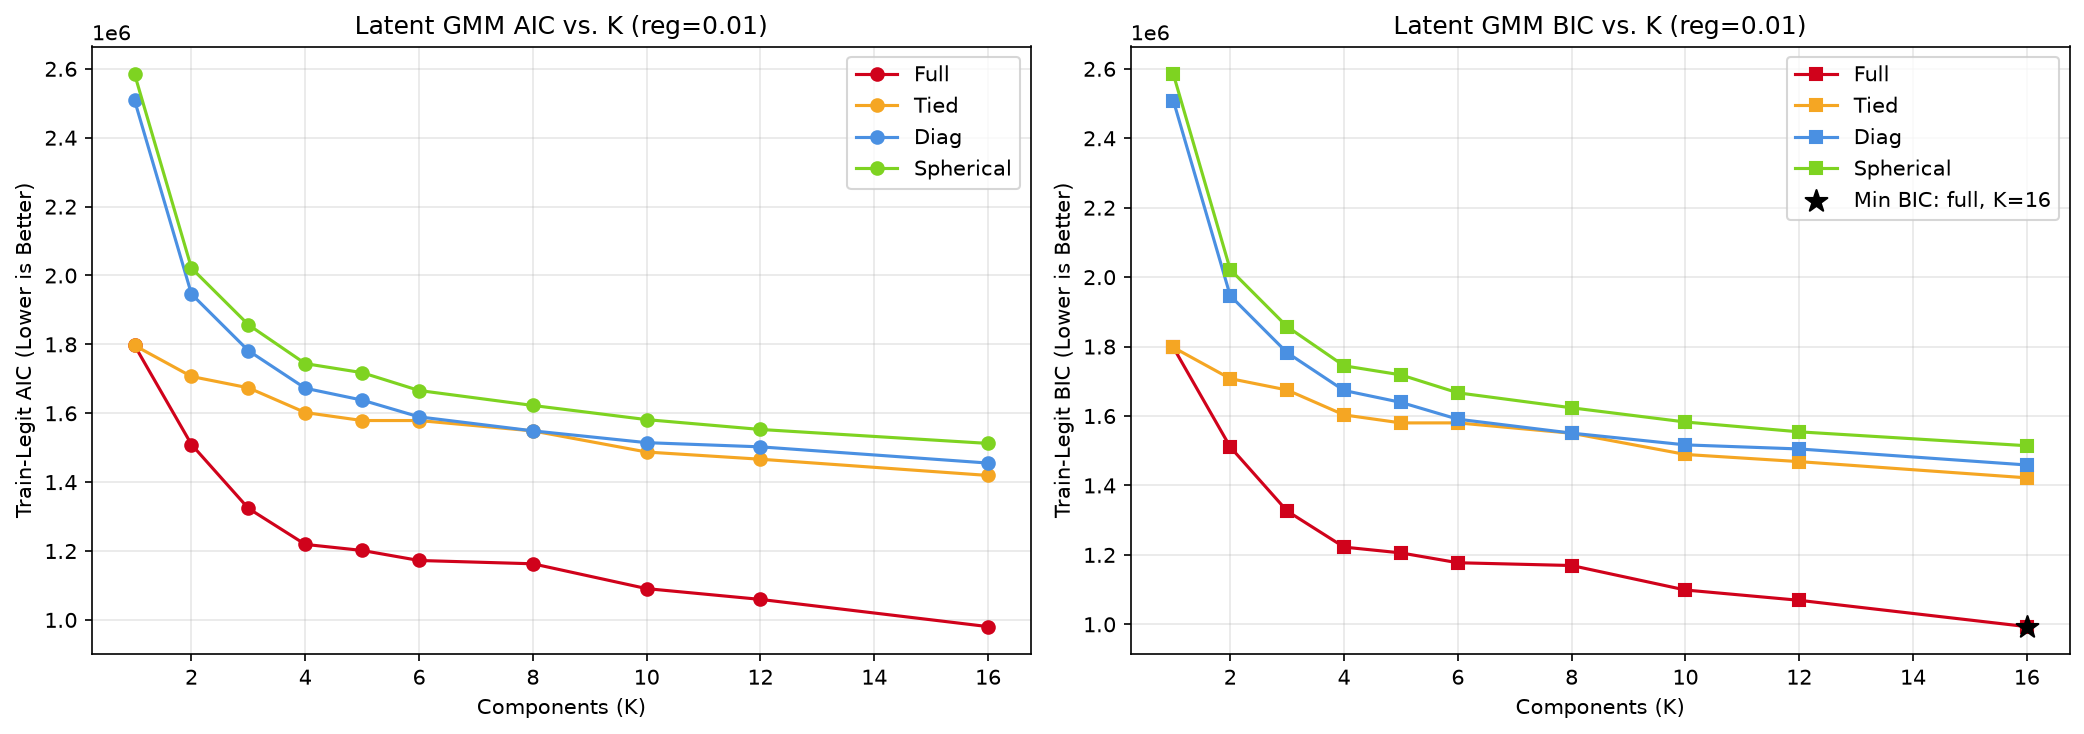

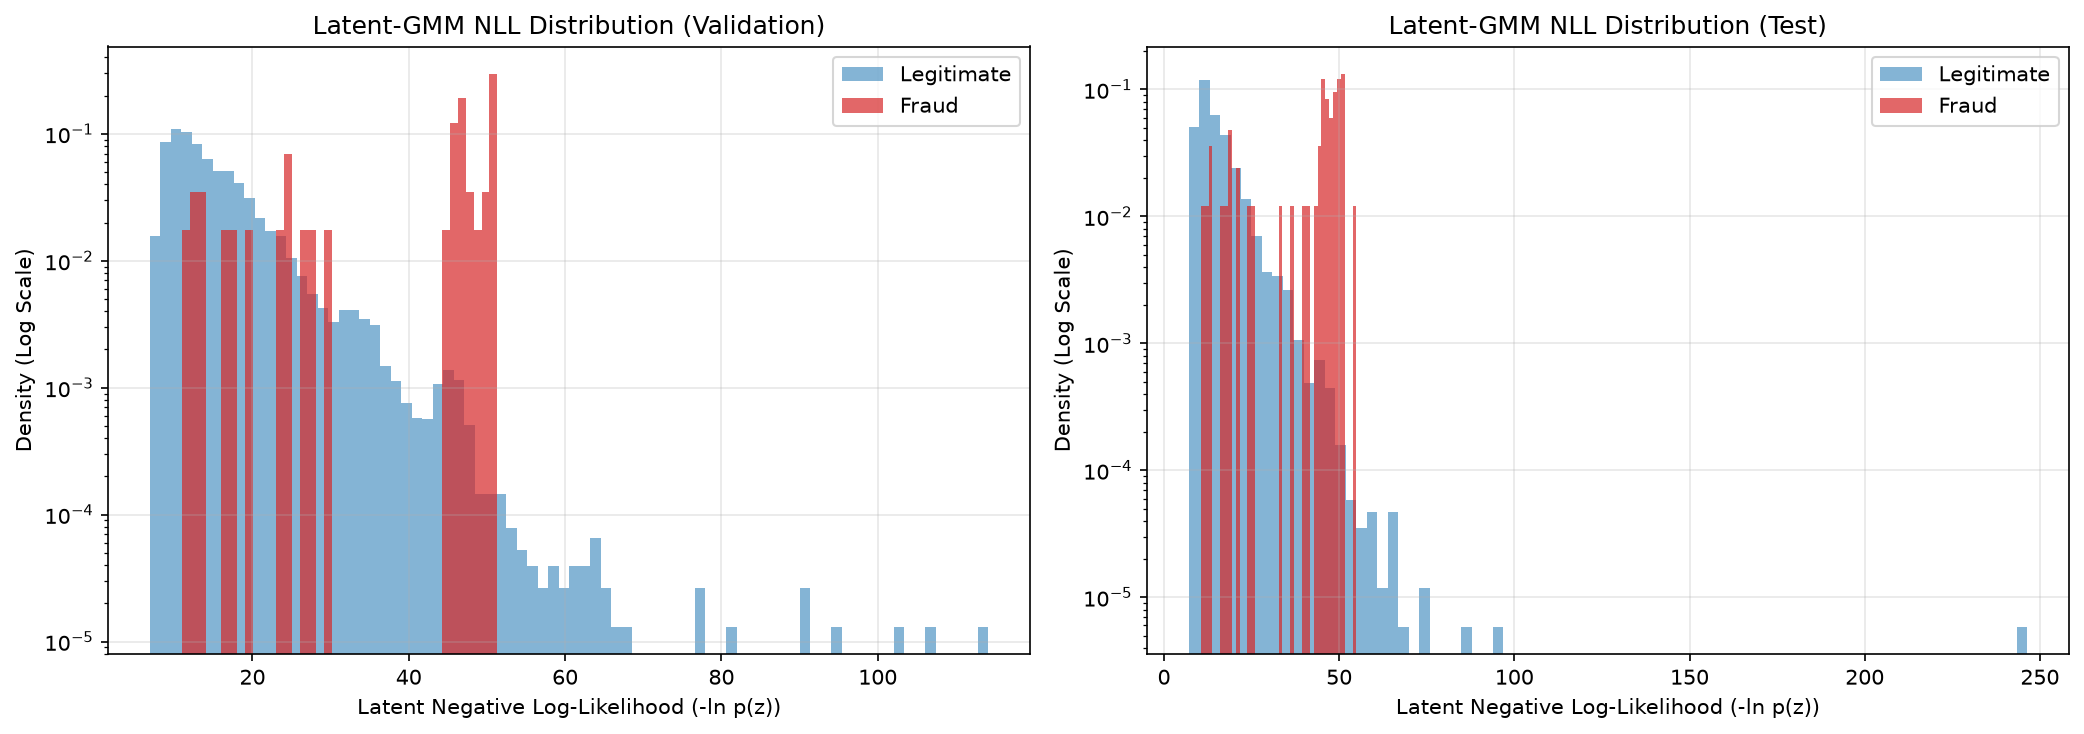

In [4]:
s_val = load_scores("hybrid_latentgmm", "val")
s_test = load_scores("hybrid_latentgmm", "test")
assert s_val.dtype == np.float32 and len(s_val) == len(splits.y_val)
assert s_test.dtype == np.float32 and len(s_test) == len(splits.y_test)
assert np.isfinite(s_val).all() and np.isfinite(s_test).all()
print(f"Score contract PASS | val PR-AUC={pr_auc(splits.y_val, s_val):.4f}, test PR-AUC={pr_auc(splits.y_test, s_test):.4f}, test Rec@0.5%={recall_at_fpr(splits.y_test, s_test, 0.005):.4f}")

print("--- Parent Comparison (95% Stratified Bootstrap CIs) ---")
display(ci_df)
print("--- Paired Bootstrap Differences (H1 - Parent) ---")
display(paired_df)

display(Image(filename=str(ROOT / "results/figures/latentgmm_aic_bic.png")))
display(Image(filename=str(ROOT / "results/figures/latentgmm_nll_distribution.png")))


## 3. Task B — Empirical Evidence (i)–(v)
### Evidence (i)–(iii): Parameter Complexity, Condition Numbers & Seed Stability

--- Parameter Counts at K=12 ---


,space,dimension,covariance_type,free_parameters,reduction_pct_vs_d31
5,ambient,30,full,5951,6.06
12,ambient,30,tied,836,4.89
19,ambient,30,diag,731,3.18
26,ambient,30,spherical,383,3.04
33,ambient,31,full,6335,0.00
40,ambient,31,tied,879,0.00
47,ambient,31,diag,755,0.00
54,ambient,31,spherical,395,0.00
61,latent,2,full,71,98.88
68,latent,2,tied,38,95.68


--- Condition Number & reg_covar Sensitivity (full cov, K=12) ---


,space,reg_covar,val_pr_auc,mean_condition_number,status
0,ambient_d31,1.000000e-07,0.667711,5.274256e+07,Stable
1,ambient_d31,1.000000e-06,0.700268,4.716634e+06,Stable
2,ambient_d31,1.000000e-05,0.699516,6.294422e+05,Stable
3,ambient_d31,1.000000e-04,0.686498,7.881607e+04,Stable
4,ambient_d31,1.000000e-03,0.704208,7.982831e+03,Stable
5,ambient_d31,1.000000e-02,0.717605,1.045609e+03,Stable
6,ambient_d31,1.000000e-01,0.708934,1.419103e+02,Stable
14,latent_d12,1.000000e-07,0.045023,8.666259e+08,Stable
15,latent_d12,1.000000e-06,0.045026,8.666408e+07,Stable
16,latent_d12,1.000000e-05,0.045043,8.667880e+06,Stable


--- 5-Seed Stability Summary (n_init=1) ---


val_pr_auc           val_recall@0.5%            \
                  mean       std            mean       std   
space                                                        
ambient_d31   0.440306  0.172346        0.701754  0.044728   
latent_d12    0.134941  0.025628        0.680702  0.041885   

            mean_condition_number             train_time_sec            
                             mean         std           mean       std  
space                                                                   
ambient_d31            885.234140  415.438560      19.107544  9.487161  
latent_d12               8.353776    0.515001       2.825211  1.717993

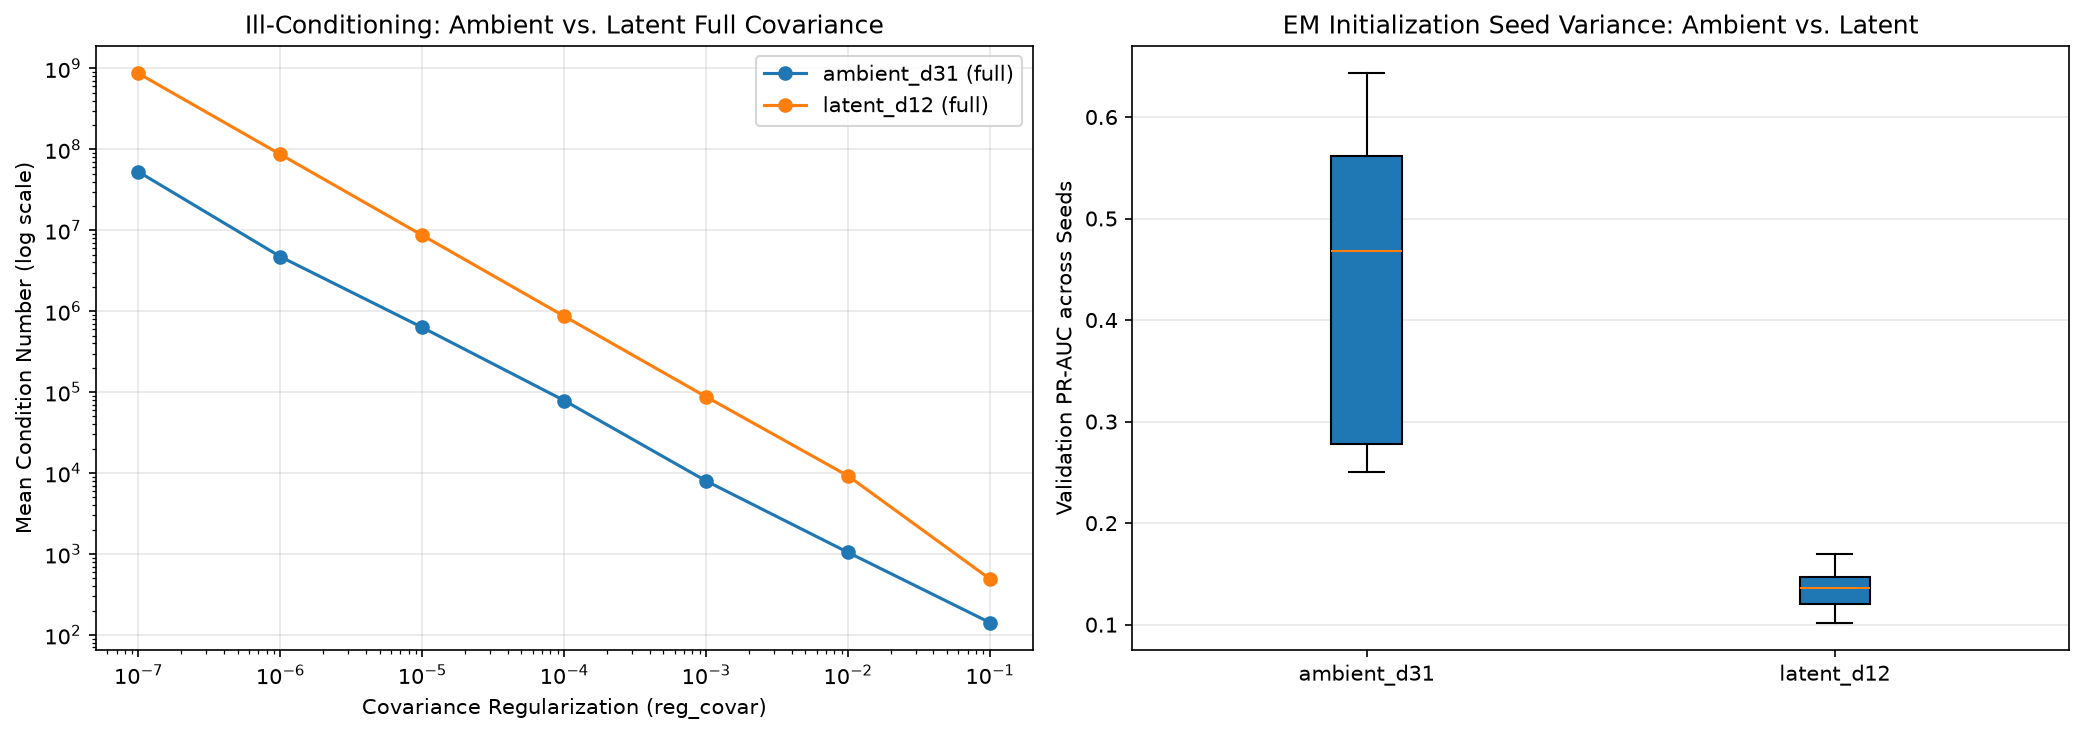

In [5]:
param_df = pd.read_csv(ROOT / "results/tables/latentgmm_param_counts.csv", index_col=0)
reg_df = pd.read_csv(ROOT / "results/tables/latentgmm_reg_covar_sensitivity.csv", index_col=0)
seed_df = pd.read_csv(ROOT / "results/tables/latentgmm_seed_stability.csv", index_col=0)

print("--- Parameter Counts at K=12 ---")
display(param_df[param_df["n_components"] == 12][["space", "dimension", "covariance_type", "free_parameters", "reduction_pct_vs_d31"]])

print("--- Condition Number & reg_covar Sensitivity (full cov, K=12) ---")
display(reg_df[reg_df["covariance_type"] == "full"][["space", "reg_covar", "val_pr_auc", "mean_condition_number", "status"]])

print("--- 5-Seed Stability Summary (n_init=1) ---")
display(seed_df.groupby("space")[["val_pr_auc", "val_recall@0.5%", "mean_condition_number", "train_time_sec"]].agg(["mean", "std"]))
display(Image(filename=str(ROOT / "results/figures/latentgmm_stability_comparison.png")))


### Evidence (iv)–(v): Latent Gaussianity, Failure Analysis & Complementarity

--- Ambient vs Latent Gaussianity Summary ---


,space,n_coords,mean_abs_skew,median_abs_skew,max_abs_skew,mean_abs_kurtosis,median_abs_kurtosis,max_abs_kurtosis,pct_mildly_gaussian,mean_shapiro_w
0,ambient_d31,31,1.739072,0.591415,9.434447,94.873457,5.882465,1254.031570,38.709677,0.835795
1,latent_d12,12,5.052991,3.777646,11.387965,84.638820,51.073615,292.772851,0.000000,0.713456


--- Top 10 Missed Validation Frauds under H1 ---


,missed_rank,row_index,latentgmm_nll,latentgmm_legit_pct,flagged_at_fpr_budget,latent_l2_norm,gmm_score,gmm_flagged,ae_score,ae_flagged,ae_dae_score,ae_dae_flagged,pca_score,pca_flagged
0,1,48141,10.9694,29.07,False,11.7484,22.4635,False,0.1257,False,0.1823,False,0.0075,False
1,2,43891,12.5732,45.45,False,15.4350,49.5978,False,0.9446,False,1.0612,False,0.0078,False
2,3,21803,12.7474,46.97,False,10.4526,11.6244,False,0.0925,False,0.1809,False,0.0003,False
3,4,51535,13.3937,52.02,False,15.8543,39.9933,False,0.4363,False,0.7648,False,0.0221,False
4,5,49008,13.9837,56.19,False,11.3000,50.9167,False,0.2261,False,0.5296,False,0.1171,False
5,6,33195,16.9955,72.56,False,8.4736,9.5984,False,0.1496,False,0.2679,False,0.0002,False
6,7,20383,17.5265,75.21,False,10.9204,44.7550,False,0.3758,False,0.8328,False,0.0509,False
7,8,26702,20.0104,84.53,False,12.1891,50.5730,False,0.4471,False,0.4741,False,0.0221,False
8,9,45069,23.4283,91.16,False,16.1331,93.5297,True,0.8320,False,1.0434,False,0.1248,False
9,10,12108,24.1041,92.29,False,17.6272,21.4551,False,0.0437,False,0.6597,False,0.0130,False


--- Alert Complementarity at FPR=0.5% ---


,parent_model,fpr_budget,n_fraud,h1_caught,parent_caught,both_caught,h1_only_caught,parent_only_caught,missed_by_both,union_recall,split
4,gmm,0.005,57,40,34,31,9,3,14,0.754386,val
5,ae,0.005,57,40,38,36,4,2,15,0.736842,val
6,ae_dae,0.005,57,40,42,40,0,2,15,0.736842,val
7,pca,0.005,57,40,41,40,0,1,16,0.719298,val
16,gmm,0.005,75,56,50,47,9,3,16,0.786667,test
17,ae,0.005,75,56,51,48,8,3,16,0.786667,test
18,ae_dae,0.005,75,56,58,56,0,2,17,0.773333,test
19,pca,0.005,75,56,58,56,0,2,17,0.773333,test


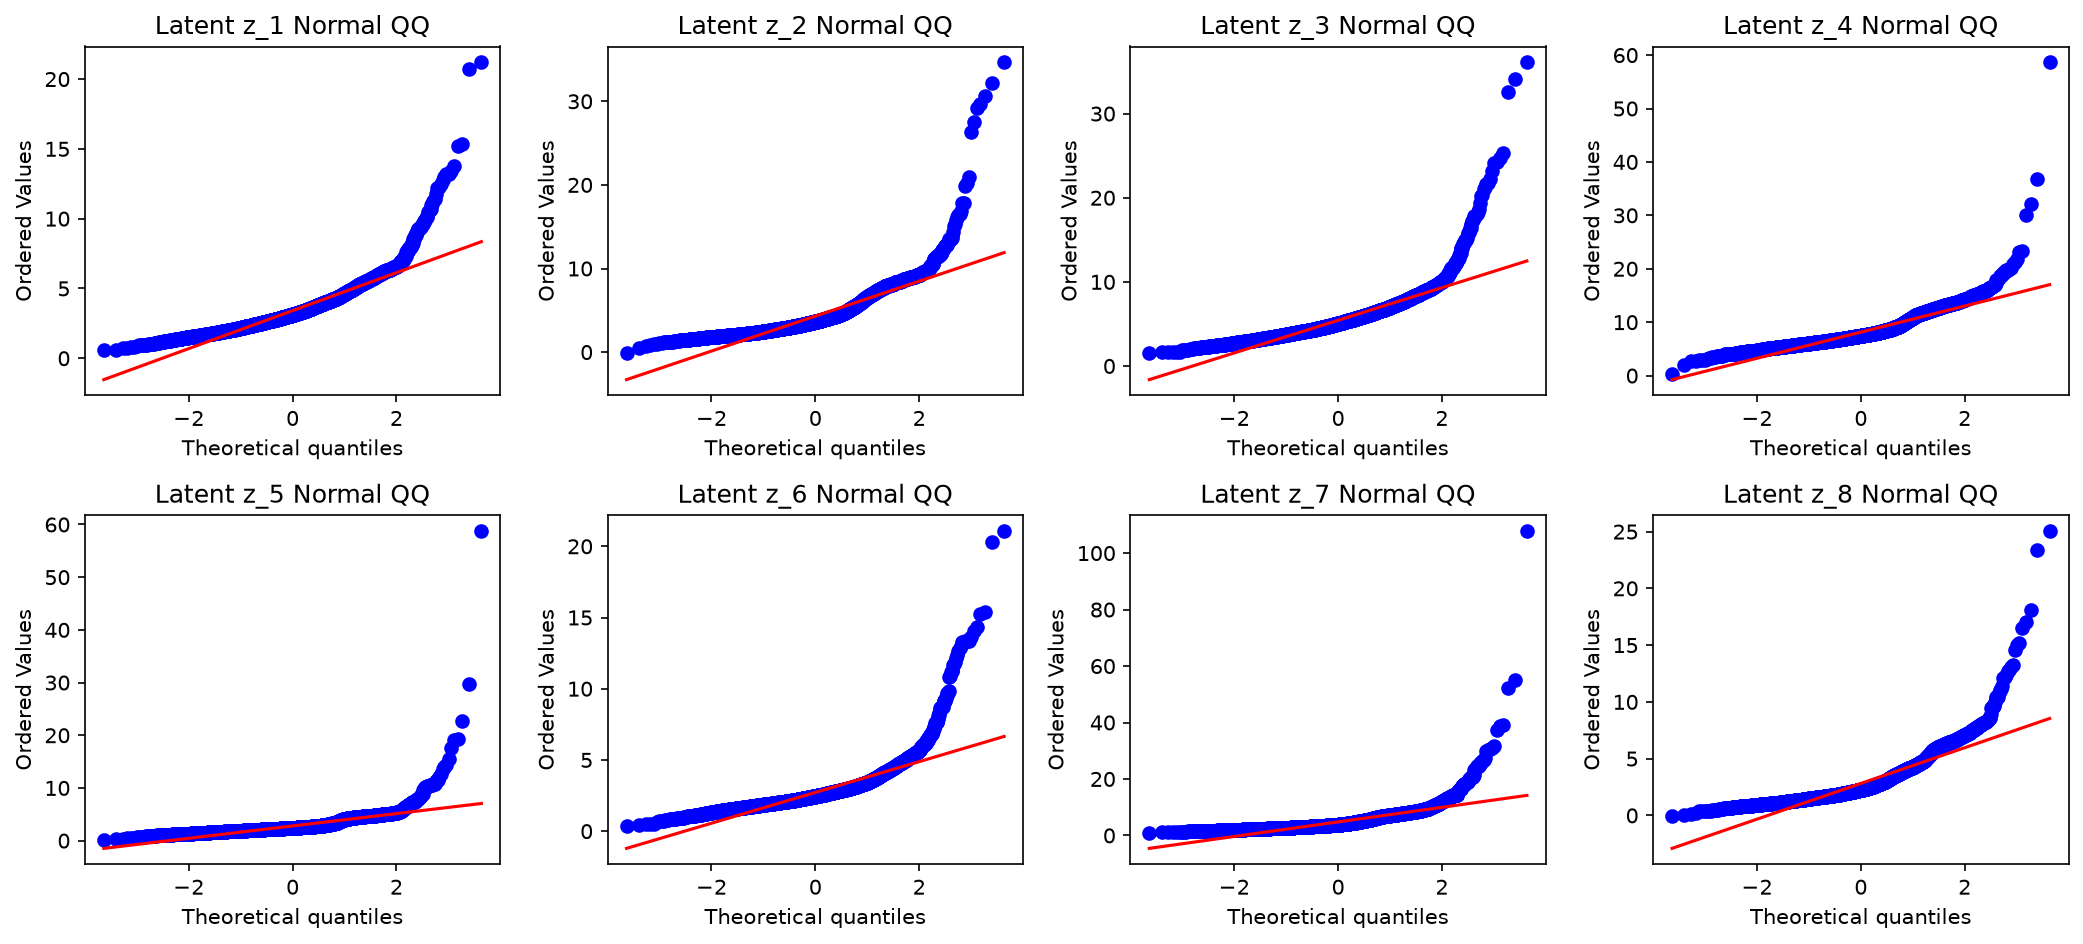

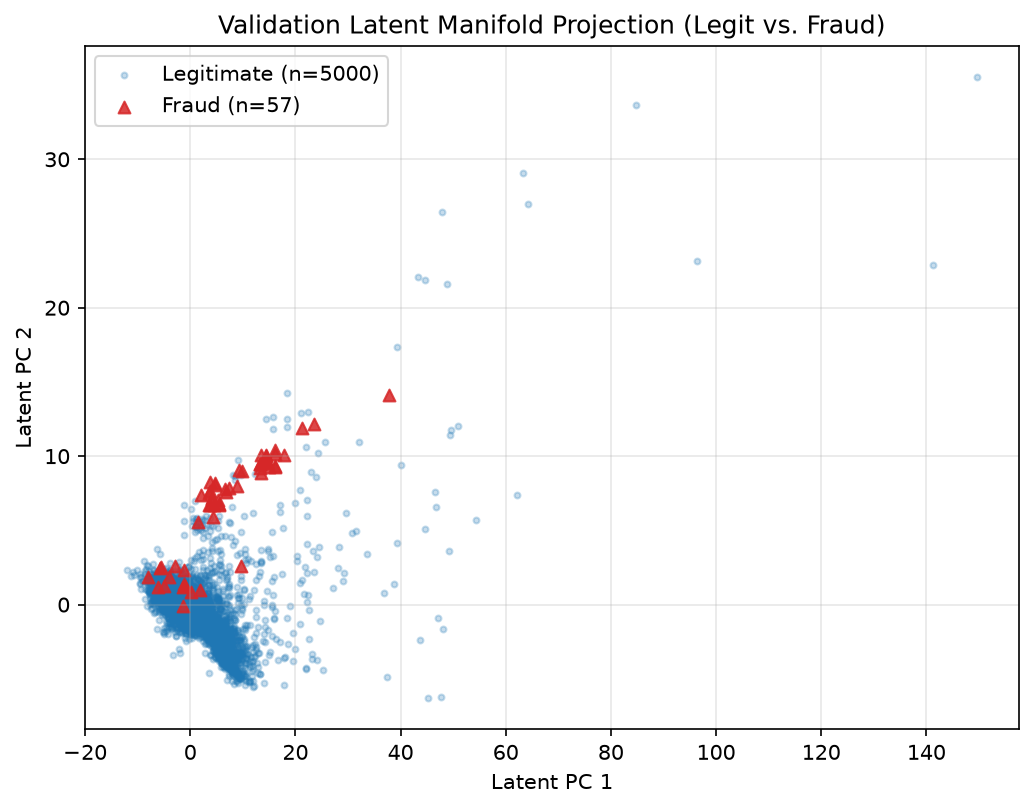

In [6]:
gauss_sum = pd.read_csv(ROOT / "results/tables/latentgmm_gaussianity_summary.csv", index_col=0)
fail_df = pd.read_csv(ROOT / "results/tables/latentgmm_failure_analysis.csv", index_col=0)
comp_df = pd.read_csv(ROOT / "results/tables/latentgmm_complementarity.csv", index_col=0)

print("--- Ambient vs Latent Gaussianity Summary ---")
display(gauss_sum)
print("--- Top 10 Missed Validation Frauds under H1 ---")
display(fail_df)
print("--- Alert Complementarity at FPR=0.5% ---")
display(comp_df[comp_df["fpr_budget"] == 0.005])

display(Image(filename=str(ROOT / "results/figures/latentgmm_qq_plots.png")))
display(Image(filename=str(ROOT / "results/figures/latentgmm_2d_projection.png")))


## 4. Task C — Multi-Dimension GMM Ablation (`k ∈ {2, 4, 8, 12, 16}` × Covariance × K × 3 Seeds)

In [7]:
ab_sum = pd.read_csv(ROOT / "results/tables/ablation_gmm_summary.csv", index_col=0)
best_per_dim = ab_sum.sort_values("val_pr_auc_mean", ascending=False).groupby("latent_dim", as_index=False).first()
print("--- Best Configuration per Latent Dimension (Selected by Val PR-AUC Mean, 3 Seeds) ---")
display(best_per_dim[["latent_dim", "covariance_type", "n_components", "free_parameters", "val_pr_auc_mean", "val_pr_auc_std", "test_pr_auc_mean", "test_pr_auc_std", "test_recall05_mean"]])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for cov, grp in ab_sum[ab_sum["n_components"] == 16].groupby("covariance_type"):
    g = grp.sort_values("latent_dim")
    ax1.errorbar(g["latent_dim"], g["val_pr_auc_mean"], yerr=g["val_pr_auc_std"], marker="o", capsize=3, label=cov.capitalize())
    ax2.errorbar(g["latent_dim"], g["test_pr_auc_mean"], yerr=g["test_pr_auc_std"], marker="s", capsize=3, label=cov.capitalize())

ax1.set_title("Task C Ablation: Validation PR-AUC vs. Latent Dim (K=16, 3 Seeds)")
ax1.set_xlabel("Latent Dimension k")
ax1.set_ylabel("Validation PR-AUC (mean ± std)")
ax1.set_xticks([2, 4, 8, 12, 16])
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.set_title("Task C Ablation: Test PR-AUC vs. Latent Dim (K=16, 3 Seeds)")
ax2.set_xlabel("Latent Dimension k")
ax2.set_ylabel("Test PR-AUC (mean ± std)")
ax2.set_xticks([2, 4, 8, 12, 16])
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(ROOT / "results/figures/latentgmm_ablation_dim.png", dpi=150, bbox_inches="tight")
plt.show()


--- Best Configuration per Latent Dimension (Selected by Val PR-AUC Mean, 3 Seeds) ---


,latent_dim,covariance_type,n_components,free_parameters,val_pr_auc_mean,val_pr_auc_std,test_pr_auc_mean,test_pr_auc_std,test_recall05_mean
0,2,full,16,95,0.005328,0.000172,0.005980,0.000375,0.013333
1,4,full,16,239,0.167424,0.029040,0.276298,0.062681,0.764444
2,8,full,16,719,0.007301,0.000638,0.011263,0.001562,0.022222
3,12,tied,16,285,0.140350,0.025110,0.244254,0.025974,0.742222
4,16,tied,16,407,0.263658,0.039054,0.414904,0.035552,0.773333


/var/folders/t5/4fr2b1k941n1blxmtyn8wh8c0000gn/T/ipykernel_73531/3768914243.py:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
